<a href="https://colab.research.google.com/github/WeridFire/QuantumComputing/blob/main/assignment2/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


In [110]:
import math
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, QuantumRegister
from qiskit.quantum_info import Statevector


def sv_from_circ(circ: QuantumCircuit) -> np.ndarray:
    """Simulate the circuit and return its state vector as a numpy array."""
    sv = Statevector(circ)
    return np.asarray(sv, dtype=np.complex128)


class QubitSystem:
    def __init__(self, statevector: np.ndarray, label: str = "Qubit System"):
        self.label = label
        self.set_statevector(statevector)

    def set_statevector(self, statevector: np.ndarray):
        sv = np.asarray(statevector, dtype=np.complex128).flatten()
        if sv.ndim != 1:
            raise ValueError("Statevector must be 1D.")
        n_states = sv.size
        n_qubits = int(round(math.log2(n_states)))
        if 2**n_qubits != n_states:
            raise ValueError("Length must be a power of 2.")
        norm = np.linalg.norm(sv)
        if norm != 0 and not np.isclose(norm, 1.0):
            sv = sv / norm

        self.n_qubits = n_qubits
        self.n_states = n_states
        self.amps  = sv
        self.prob  = np.abs(sv)**2
        self.phase = np.angle(sv)

    def viz_circle(self, max_cols: int = 8, figsize_scale: float = 2.3):
        cols = max(1, min(max_cols, self.n_states))
        rows = int(math.ceil(self.n_states / cols))

        fig, axes = plt.subplots(
            rows, cols,
            figsize=(cols*figsize_scale, rows*(figsize_scale+0.2))
        )
        axes = np.atleast_2d(axes)

        def bitstr(i: int, n: int) -> str:
            return format(i, f"0{n}b")

        for idx in range(rows * cols):
            r, c = divmod(idx, cols)
            ax = axes[r, c]
            ax.set_aspect("equal")
            ax.set_xlim(0, 1); ax.set_ylim(0, 1)
            ax.axis("off")

            if idx >= self.n_states:
                ax.set_visible(False)
                continue

            ax.add_patch(plt.Circle((0.5, 0.5), 0.48, fill=False, lw=1.0, alpha=0.5))

            radius = 0.48 * np.sqrt(self.prob[idx])
            ax.add_patch(plt.Circle((0.5, 0.5), radius, alpha=0.25))

            if self.prob[idx] > 1e-10:
                angle = self.phase[idx]
                L = 0.45
                x2 = 0.5 + L * np.cos(angle)
                y2 = 0.5 + L * np.sin(angle)
                ax.arrow(0.5, 0.5, x2 - 0.5, y2 - 0.5,
                         head_width=0.03, head_length=0.05, length_includes_head=True)

            ax.set_title(f"|{bitstr(idx, self.n_qubits)}⟩", fontsize=10)

        fig.suptitle(self.label, fontsize=12)
        plt.tight_layout()
        plt.show()

In [111]:
def increment(qc, q):
    """Add 1 (mod 2^n) to the register q, q[0] = least significant bit."""
    n = len(q)
    for target in reversed(range(n)):
        controls = list(range(target))
        if len(controls) == 0:
            qc.x(target)
        else:
            qc.mcx(controls, target)


def decrement(qc, q):
    """Subtract 1 (mod 2^n): the increment gates in reverse order."""
    n = len(q)
    for target in range(n):
        controls = list(range(target))
        if len(controls) == 0:
            qc.x(target)
        else:
            qc.mcx(controls, target)


def basis_state(value, n=3):
    """Circuit that prepares the n-qubit basis state |value> (q0 = LSB)."""
    qc = QuantumCircuit(n)
    for i in range(n):
        if (value >> i) & 1:
            qc.x(i)
    return qc


def read_value(qc):
    """For a circuit whose final state is a single basis state, return its integer value."""
    return int(np.argmax(np.abs(sv_from_circ(qc))))


def to_signed(value, n=3):
    """Two's complement reading of an n-bit value."""
    if value >= 2**(n-1):
        return value - 2**n
    return value


def circle_plot(circ, label):
    """Shortcut: simulate the circuit and show its state in circle notation."""
    QubitSystem(sv_from_circ(circ), label=label).viz_circle()

# Task 1 - Quantum Arithmetics

Implement 3-qubit increment and decrement operators using IBM Qiskit, then inspect the states using circle notation.


## Task 1.1 - Increment and Decrement Operator

1. Prepare a superposition of quantum states using HAD QPU instructions. You can decide freely which superposition. This will determine the concurrent increment or decrement operator.
2. Plot the quantum states using the circle notation.
   IBM Qiskit does not support visualization for this step; you will need to implement a Python routine to visualize the quantum states of our qubit. You can find a Python code to perform this task at 1.1.1 - Python Code for Circle Notation.
3. Perform an increment operation (by 1) +=
4. Plot the quantum states using the circular notation
5. Perform a decrement operation (by 1) -=
6. Plot the quantum states using the circular notation

> What to include. The chosen initial superposition, both circuits, and all three circle-notation plots.


### Our Solution


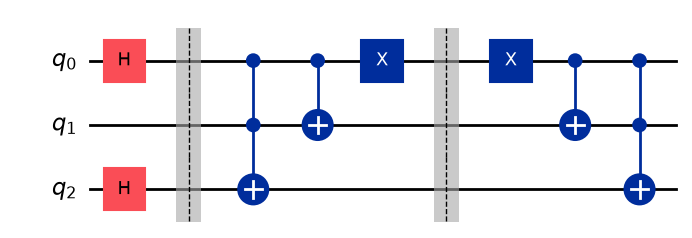

In [112]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
# ============================================================
# INCREMENT / DECREMENT GATE BUILDERS (3-qubit, q0=LSB, q2=MSB)
# ============================================================

def increment_circuit(n=3):
    """Build a mod-2^n increment circuit: chain of MCX gates, MSB down to LSB."""
    qc = QuantumCircuit(n, name="INC")
    for target in reversed(range(n)):
        controls = list(range(target))  # all lower qubits control this one
        if len(controls) == 0:
            qc.x(target)
        else:
            qc.mcx(controls, target)
    return qc

def decrement_circuit(n=3):
    """Decrement = increment circuit run in reverse (all gates are self-inverse)."""
    qc = QuantumCircuit(n, name="DEC")
    for target in range(n):
        controls = list(range(target))
        if len(controls) == 0:
            qc.x(target)
        else:
            qc.mcx(controls, target)
    return qc

INC = increment_circuit(3)
DEC = decrement_circuit(3)


qc_full = QuantumCircuit(3)
qc_full.h(0); qc_full.h(2); qc_full.barrier()
qc_full.compose(INC, inplace=True); qc_full.barrier()
qc_full.compose(DEC, inplace=True)
display(qc_full.draw("mpl"))



Initial state: [0.5+0.j 0.5+0.j 0. +0.j 0. +0.j 0.5+0.j 0.5+0.j 0. +0.j 0. +0.j]


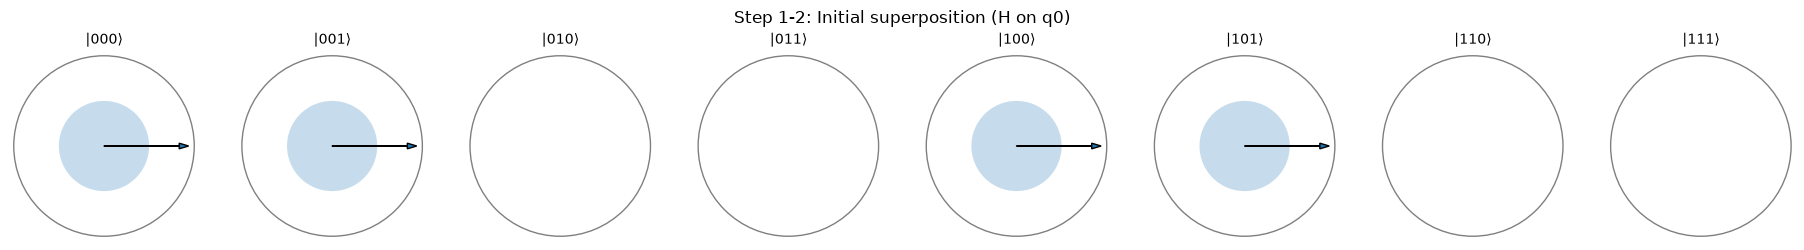

After increment: [0. +0.j 0.5+0.j 0.5+0.j 0. +0.j 0. +0.j 0.5+0.j 0.5+0.j 0. +0.j]


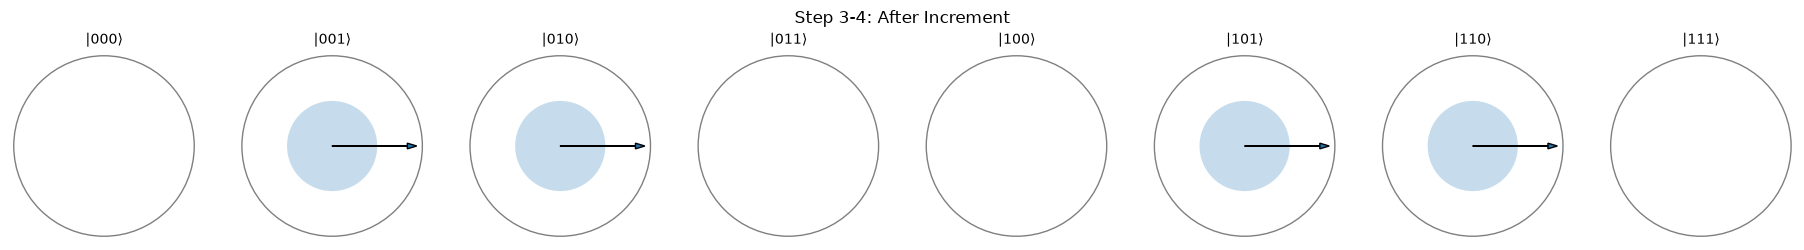

After decrement: [0.5+0.j 0.5+0.j 0. +0.j 0. +0.j 0.5+0.j 0.5+0.j 0. +0.j 0. +0.j]


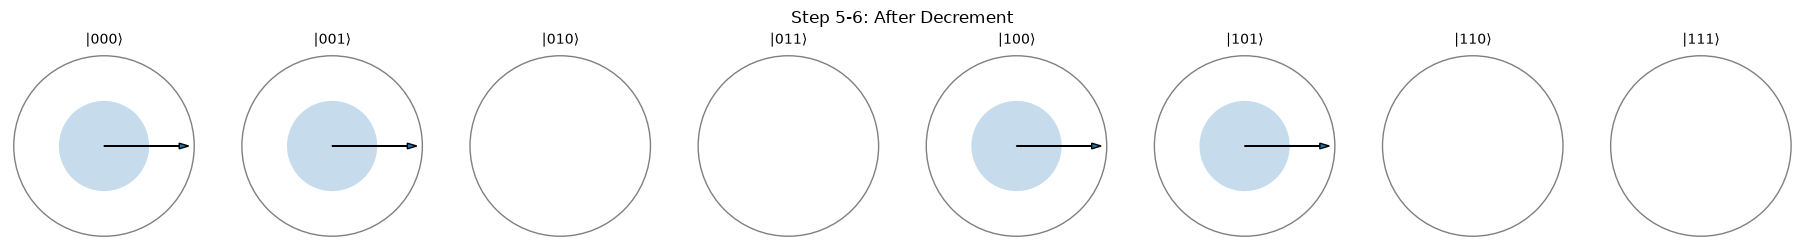

In [113]:

# ============================================================
# TASK 1.1 STEPS
# ============================================================

# Step 1-2: prepare a superposition, plot circle notation
qc = QuantumCircuit(3)
qc.h(0)
qc.h(2)

sv0 = sv_from_circ(qc)
print("\nInitial state:", np.round(sv0, 4))
QubitSystem(sv0, label="Step 1-2: Initial superposition (H on q0)").viz_circle()

# Step 3-4: increment, plot
qc_inc = qc.compose(INC)
sv1 = sv_from_circ(qc_inc)
print("After increment:", np.round(sv1, 4))
QubitSystem(sv1, label="Step 3-4: After Increment").viz_circle()

# Step 5-6: decrement, plot
qc_dec = qc_inc.compose(DEC)
sv2 = sv_from_circ(qc_dec)
print("After decrement:", np.round(sv2, 4))
QubitSystem(sv2, label="Step 5-6: After Decrement").viz_circle()


## Task 1.2 - Overflow, Underflow, and Negative Numbers

1. What happens on overflow during increment or underflow during decrement? Show both with an experiment.
2. Do increment and decrement also work with negative integers? Motivate the answer with an example.

> What to include. Overflow and underflow experiments, plus one explained negative-number example.


### Our Solution


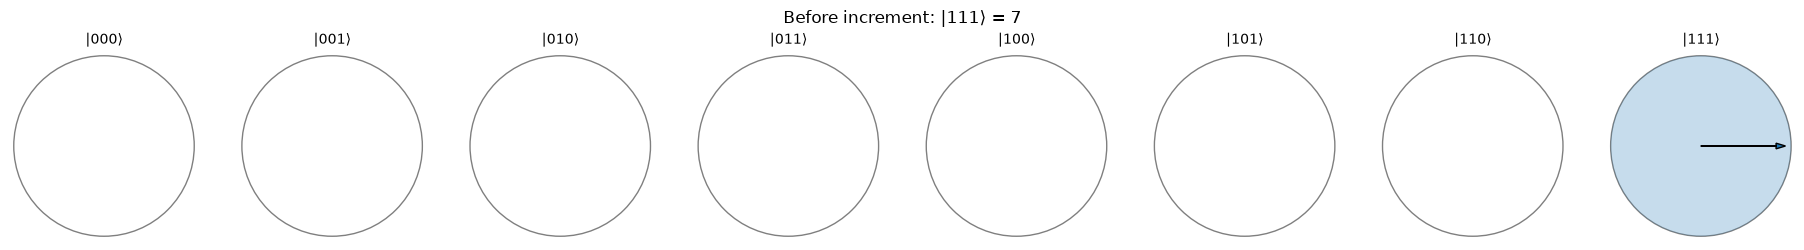

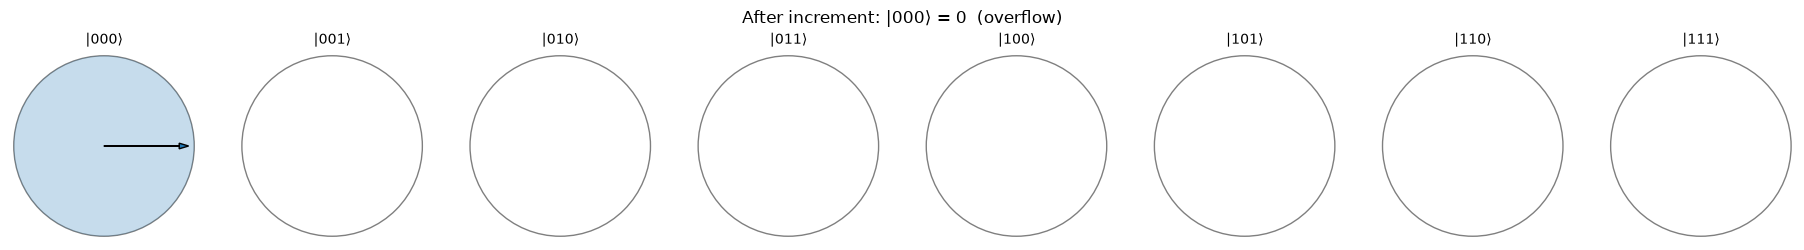

7 + 1 -> 0


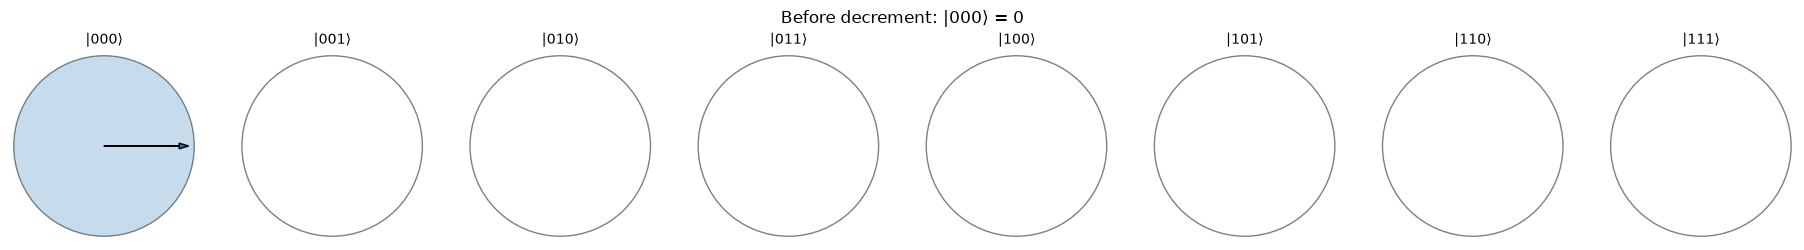

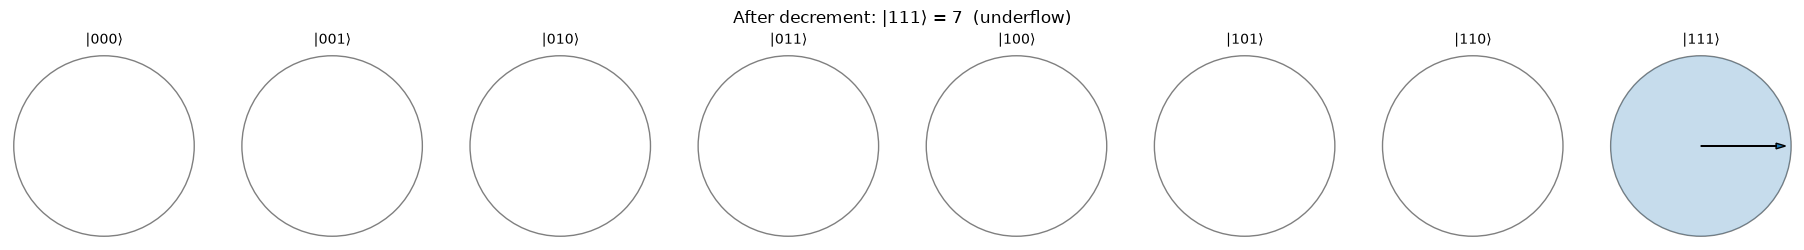

0 - 1 -> 7


In [114]:
# Overflow: 7 + 1
q = [0, 1, 2]
qc = basis_state(7)
circle_plot(qc, "Before increment: |111⟩ = 7")
increment(qc, q)
circle_plot(qc, "After increment: |000⟩ = 0  (overflow)")
print("7 + 1 ->", read_value(qc))

# Underflow: 0 - 1
q = [0, 1, 2]
qc = basis_state(0)
circle_plot(qc, "Before decrement: |000⟩ = 0")
decrement(qc, q)
circle_plot(qc, "After decrement: |111⟩ = 7  (underflow)")
print("0 - 1 ->", read_value(qc))


I tested both edges of the 3-qubit range:

Overflow: started from |111⟩ = 7 and incremented. Result was |000⟩ = 0, so 7 + 1 -> 0.

Underflow: started from |000⟩ = 0 and decremented. Result was |111⟩ = 7, so 0 - 1 -> 7.

The circle plots confirm the amplitude just moves to the other end. This happens because 3 qubits can only hold values 0 to 7, and there's no 4th qubit to catch the carry or borrow. So the circuits do arithmetic mod 8: going past 7 or below 0 simply wraps around. Nothing breaks — since the circuit is reversible, no information is lost, the value just loops.


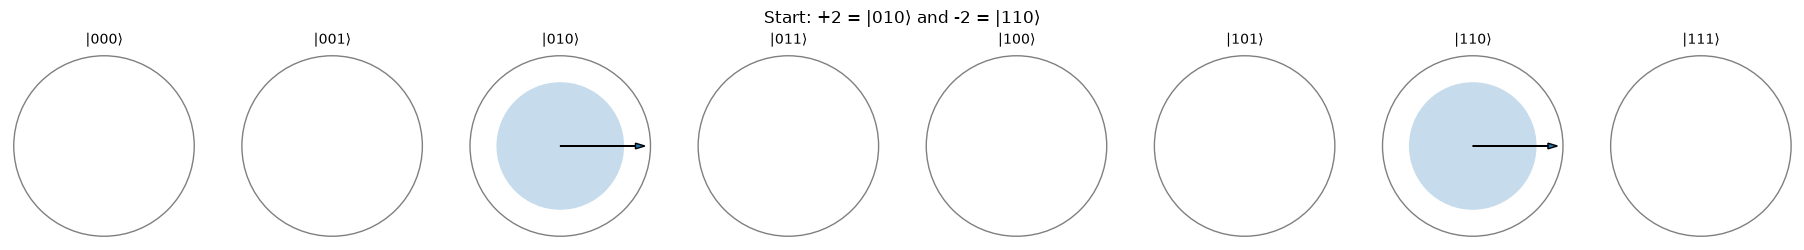

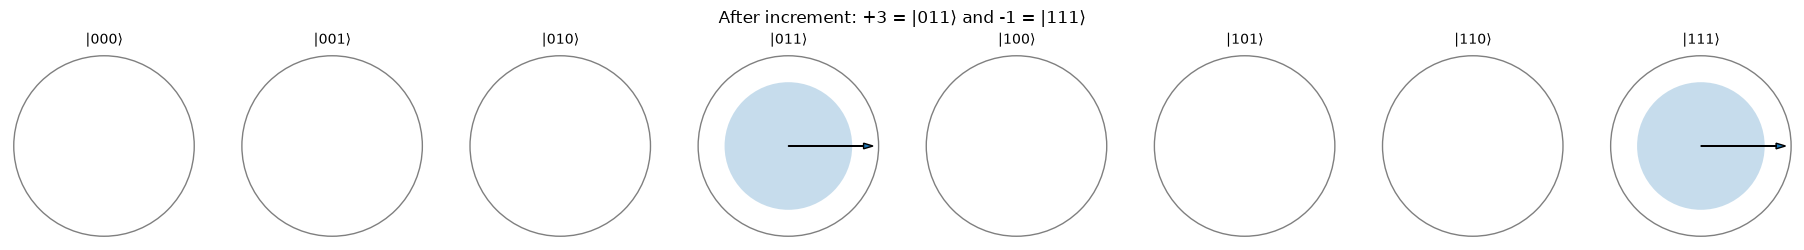

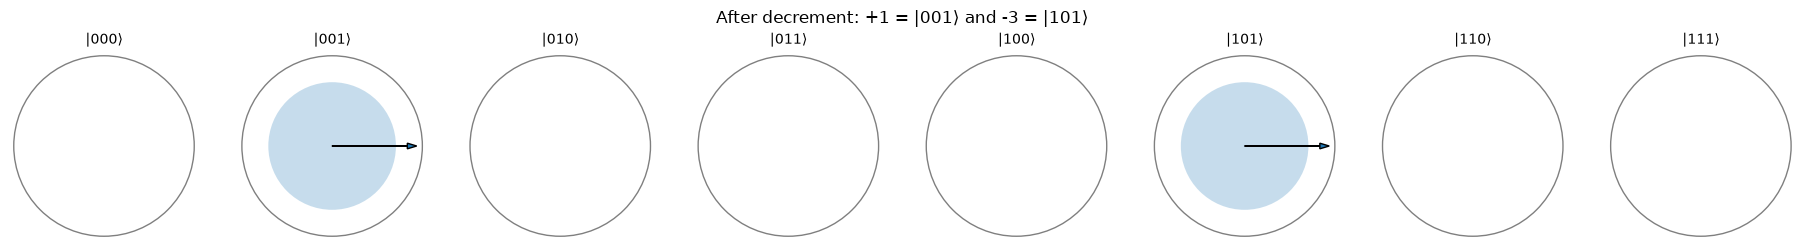

  x | x+1 | x-1
  0 |   1 |  -1
  1 |   2 |   0
  2 |   3 |   1
  3 |  -4 |   2
 -4 |  -3 |   3
 -3 |  -2 |  -4
 -2 |  -1 |  -3
 -1 |   0 |  -2


In [115]:
def plus_minus_two():
    """Superposition of +2 (|010>) and -2 (|110>)."""
    qc = QuantumCircuit(3)
    qc.x(1)   # value 2
    qc.h(2)   # add 0 or 4 -> 2 or 6, and 6 means -2 in two's complement
    return qc

qc = plus_minus_two()
circle_plot(qc, "Start: +2 = |010⟩ and -2 = |110⟩")

qc_inc = plus_minus_two()
increment(qc_inc, q)
circle_plot(qc_inc, "After increment: +3 = |011⟩ and -1 = |111⟩")

qc_dec = plus_minus_two()
decrement(qc_dec, q)
circle_plot(qc_dec, "After decrement: +1 = |001⟩ and -3 = |101⟩")

print("  x | x+1 | x-1")
for value in range(8):
    inc = basis_state(value)
    increment(inc, q)
    dec = basis_state(value)
    decrement(dec, q)
    print(f"{to_signed(value):3d} | {to_signed(read_value(inc)):3d} | {to_signed(read_value(dec)):3d}")

Yes, they work. If we read the bits as two's complement:

bits 000 001 010 011 100 101 110 111
unsigned 0 1 2 3 4 5 6 7
two's complement 0 1 2 3 −4 −3 −2 −1

The circuit doesn't know about signs — it just does mod-8 arithmetic, and two's complement happens to be the same thing. For example, −1 is stored as |111⟩, and incrementing it gives |000⟩ = 0, which is correct (−1 + 1 = 0).

Example: I prepared a superposition of +2 = |010⟩ and −2 = |110⟩. Incrementing gave +3 and −1; decrementing gave +1 and −3 — both correct, and both shifted in parallel by the same circuit.

So increment and decrement work fine on negative numbers, as long as the answer stays inside [−4, 3]. Outside that range, we get the same wraparound as the unsigned case (3 + 1 = −4, −4 − 1 = 3).


# Task 2 - Quantum Fourier Transform

Build a 4-qubit preparation circuit and QFT using Hadamard and controlled-phase gates, then analyze the resulting state.

The quantum Fourier transform is a crucial building block of many quantum algorithms, from Shor’s factoring algorithm to quantum phase estimation and simulations. As we saw in the lectures, QFT, like the conventional DFT and FFT, can be used to transform a function from the time domain into the frequency domain. Information about the periodic behavior of a function can be, for instance, encoded in the phases of the quantum states.

The goal of this exercise is to compute a 4-qubit QFT on a sinusoidal signal (encoded in the phase) using IBM Qiskit and plot the resulting state. As part of this task, develop a four-qubit QFT and preparation circuit as in the circuit below.


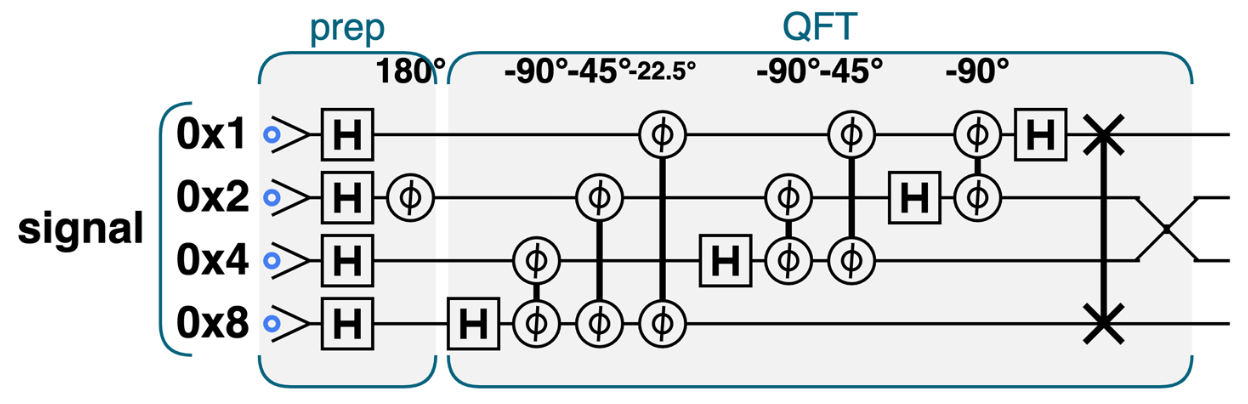


> Note that the IBM Qiskit provides a QFT function without implementing it from scratch. However, the Qiskit QFT code has a different ordering, as explained in the textbook, as pointed out in this GitHub issue: https://github.com/Qiskit/qiskit/pull/4849.


## Task 2.1 - QFT and Preparation Circuit

- Briefly describe the preparation circuit and QFT design.
- Print the complete circuit diagram.


### Our Solution


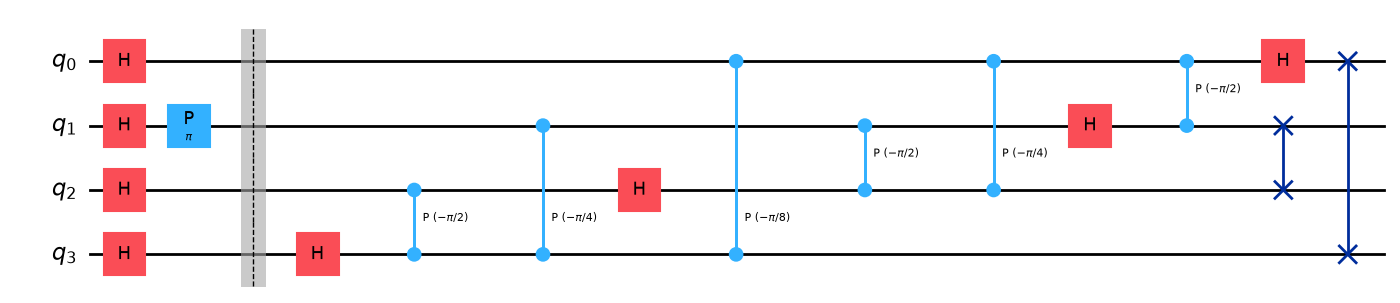

In [116]:
N = 4

def prepare_signal(qc):
    """Preparation: H on every qubit, then a PHASE(180°) gate on q1."""
    for qubit in range(N):
        qc.h(qubit)
    qc.p(np.pi, 1)


def qft_circuit(qc):
    """4-qubit QFT built from H, controlled-phase, and SWAP gates."""
    for target in reversed(range(N)):
        qc.h(target)
        for control in reversed(range(target)):
            angle = -np.pi / 2 ** (target - control)   # -90°, -45°, -22.5°
            qc.cp(angle, control, target)
    # Reverse qubit order
    qc.swap(0, 3)
    qc.swap(1, 2)


full_circuit = QuantumCircuit(N, name="prep + QFT")
prepare_signal(full_circuit)
full_circuit.barrier()   # visual separator between prep and QFT
qft_circuit(full_circuit)
full_circuit.draw("mpl")

Preparation circuit
The preparation circuit applies a Hadamard gate to each of the four qubits, putting the register into a uniform superposition over all 16 basis states — every value from |0000⟩ to |1111⟩ gets the same amplitude of 1/4.

After the Hadamards, a single-qubit phase gate P(180°) = P(π) is applied to q₁ (0x2). This phase gate flips the sign of every basis state in which q₁ = 1 — that is, the amplitude of those states gets multiplied by e^{iπ} = -1, while all other states keep their original +1 sign.

The result is a state whose amplitudes are all equal, but whose phases carry a periodic signal: values of k with the 0x2 bit set get a -1 phase, the others get +1. In the register-value domain k = 0…15, this phase pattern oscillates with a well-defined frequency — this is the "sinusoidal signal encoded in the phase" that the assignment asks us to feed into the QFT.


QFT circuit
The 4-qubit QFT is built from scratch using only H, controlled-phase (CP), and SWAP gates. We process the qubits in order from the most significant (q₃ = 0x8) down to the least significant (q₀ = 0x1). For each target qubit q_k, we apply an H, followed by controlled-phase gates from every lower-significance qubit q_j (with j < k), using the angle -π / 2^(k-j).

The resulting angles are:

-90° (= -π/2) for k − j = 1

-45° (= -π/4) for k − j = 2

-22.5° (= -π/8) for k − j = 3

These match the angle labels in the assignment diagram. The negative sign corresponds to the convention chosen in the assignment: it makes our circuit the complex conjugate of the standard library QFT, but produces the same physical transformation up to an overall phase.

Finally, we apply two SWAP gates (q₀ ↔ q₃ and q₁ ↔ q₂) to reverse the qubit order. Qiskit uses little-endian ordering (qubit 0 is the least significant bit), and the standard QFT decomposition computes the transform assuming the opposite order. The swaps restore the correct bit-ordering so the QFT output follows Qiskit's little-endian convention — the same "swap vs. reverse_bits" issue discussed in the linked GitHub PR.

We deliberately do not use the library QFT function, because — as the assignment notes — its internal bit-ordering and phase conventions differ from what the task's diagram specifies. Building the QFT from primitive gates keeps our circuit exactly aligned with the assignment figure.


## Task 2.2 - Circle Notation

1. Prepare the input and plot it using circle notation.
2. Identify the signal prepared by the circuit.
3. Perform the QFT and plot the resulting state using circle notation.

> What to include. Circle plots before and after the QFT, and an answer identifying the input signal.


### Our Solution


=== State after preparation (before QFT) ===


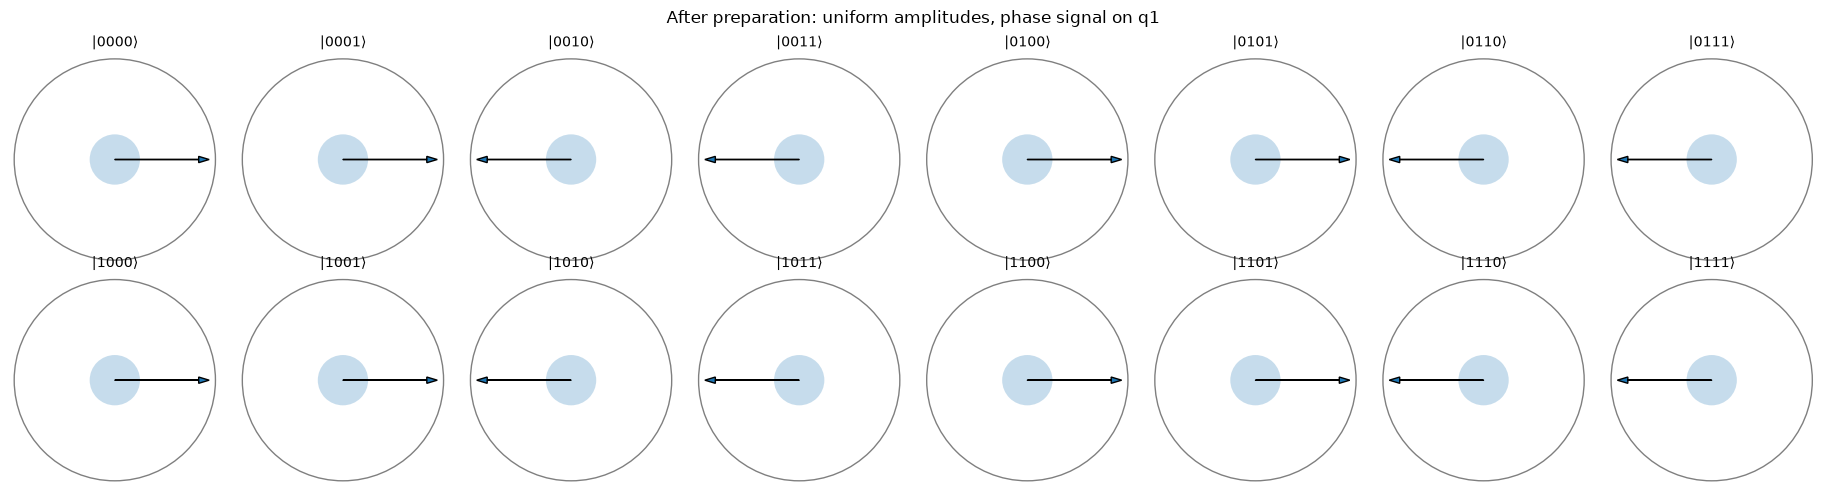


=== State after QFT ===


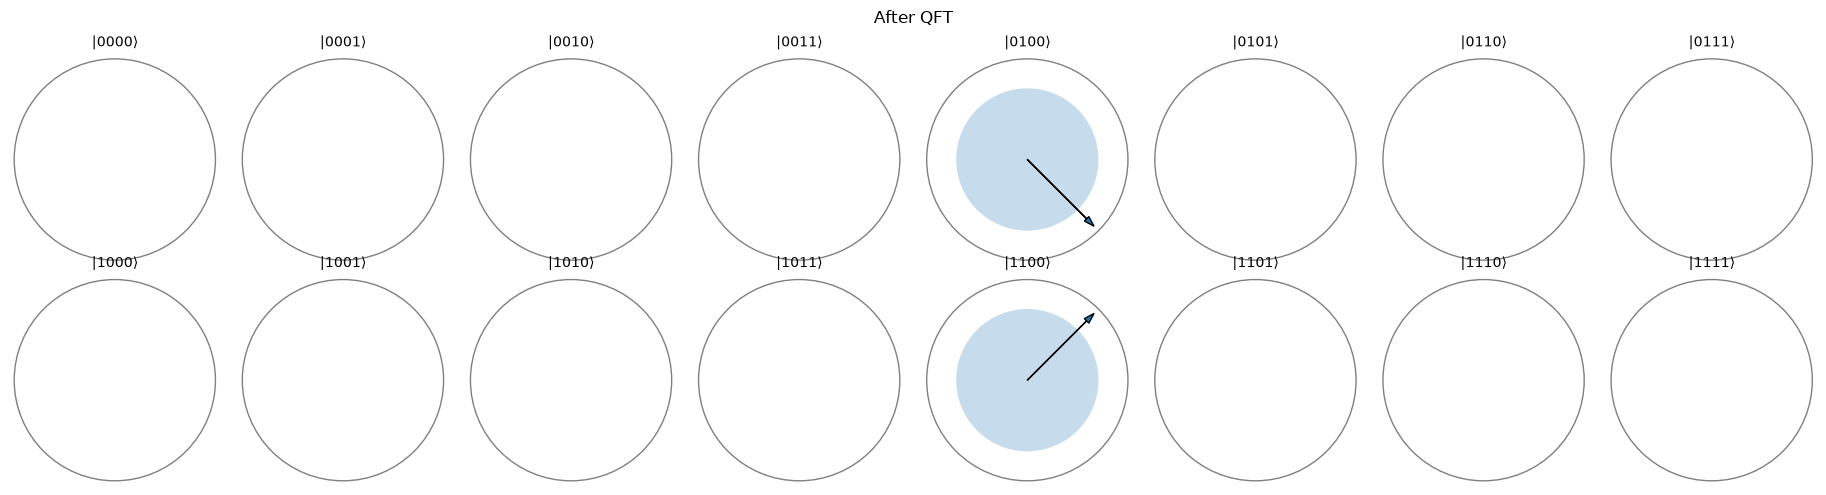

In [117]:
# ---------- Step 1: state after preparation ----------
prep_only = QuantumCircuit(N, name="prep")
prepare_signal(prep_only)

print("=== State after preparation (before QFT) ===")
circle_plot(prep_only, "After preparation: uniform amplitudes, phase signal on q1")


# ---------- Step 3: state after QFT ----------
full = QuantumCircuit(N, name="prep + QFT")
prepare_signal(full)
full.barrier()
qft_circuit(full)

print("\n=== State after QFT ===")
circle_plot(full, "After QFT")

Input state (after preparation). All 16 basis states have the same amplitude 1/4 (uniform disk sizes), but the phase arrows alternate depending on q₁: states where q₁ = 1 (values 2, 3, 6, 7, 10, 11, 14, 15) point left (phase π), all others point right (phase 0).


After the QFT. The QFT detects this frequency and concentrates the amplitude onto the matching basis state. In your plot the peak lands on |0100⟩ (value 4) and |1100⟩ (value 12) — the two states representing frequency 4 in the 4-qubit register. Both have equal probability, and their arrows point in opposite directions, which is the standard signature of a pure cosine/sine pair at that frequency. All other basis states are empty, confirming the QFT has isolated the input's single frequency component.


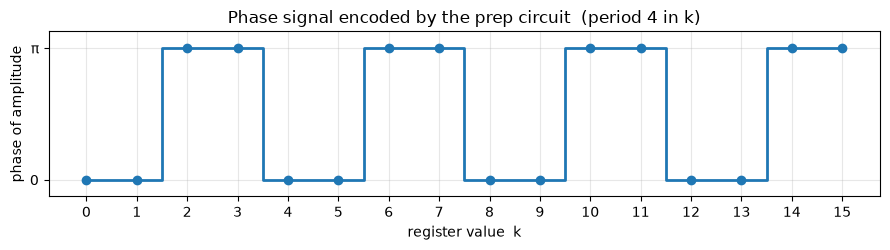

In [118]:
import matplotlib.pyplot as plt
import numpy as np

# Phase of each basis state after the prep circuit
# q1 = 1  ->  phase = π  (arrow left)
# q1 = 0  ->  phase = 0  (arrow right)
k = np.arange(16)
phase = np.array([np.pi if (i >> 1) & 1 else 0.0 for i in k])

fig, ax = plt.subplots(figsize=(9, 2.6))

# Draw the phase as a step (square wave) pattern
ax.step(k, phase, where="mid", color="C0", linewidth=2)
ax.scatter(k, phase, color="C0", zorder=3)

# Cosmetics
ax.set_xticks(k)
ax.set_yticks([0, np.pi])
ax.set_yticklabels(["0", "π"])
ax.set_xlabel("register value  k")
ax.set_ylabel("phase of amplitude")
ax.set_title("Phase signal encoded by the prep circuit  (period 4 in k)")
ax.grid(True, alpha=0.3)
ax.set_ylim(-0.4, np.pi + 0.4)

plt.tight_layout()
plt.show()

The signal. The phase pattern over the register value k = 0…15 is a square wave with period 4 — i.e., a sinusoid of frequency 4 encoded in the phases.


## Task 2.3 - Discussion

Discuss the results briefly and compare the QFT with the traditional DFT and FFT.


### Our Solution


Discussion of the results
The experiment confirms the QFT behaves as theory predicts. The preparation circuit encoded a frequency-4 signal into the phases of the 16 basis states, which showed up in the circle plot as an alternating pattern of left/right arrows with all disk sizes equal — the amplitude carries no frequency information, only the phase does. After applying the QFT, the amplitude concentrated entirely onto |0100⟩ and |1100⟩ — the two basis states corresponding to frequency 4 in a 4-qubit register. All other states became empty. In other words, the QFT moved the frequency information from the phases (invisible to a computational-basis measurement) into the magnitudes (directly readable). This is exactly the mechanism behind phase estimation and the reason QFT is the core of Shor's algorithm.


QFT vs. DFT and FFT
The QFT computes the same mathematical transformation as the classical DFT — it takes an N = 2ⁿ element signal and returns its discrete Fourier coefficients. What changes is the domain: the DFT operates on a classical array, while the QFT operates on the amplitudes of a quantum register. This has two important consequences. First, the QFT uses only O(n²) quantum gates, compared to the FFT's O(N log N) = O(n · 2ⁿ) classical operations — an exponential reduction in gate count. Second, this speedup is not free: preparing an arbitrary input state and reading out an arbitrary output state each require exponentially many operations, so the QFT alone does not beat the FFT for generic signal-processing tasks. Its real power appears in algorithms where the input has special structure (like our frequency-4 signal) and only a few output amplitudes matter — Shor's factoring algorithm and quantum phase estimation are the canonical examples. In that sense the QFT is not a "faster FFT," but a fundamentally different primitive that manipulates quantum amplitudes in superposition.

The QFT gate count is computed directly from our Task 2.1 circuit: 4 Hadamards (one per qubit), 6 controlled-phase gates (from the triangular cascade), and 2 SWAPs at the end, for 12 active gates plus one barrier. For n = 4, this matches the theoretical O(n²) ≈ n(n-1)/2 + n + n/2 = 6 + 4 + 2 = 12.


# Bonus Exercise - Discrete Quantum Walk on a Line


In this bonus exercise, you will implement and investigate the Discrete Quantum Walk (DQW) algorithm using Qiskit or Cirq or another quantum computing software of your choice.

A quantum walk is the quantum analog of a classical random walk, but with underlying quantum effects, such as interference. It can be used in various quantum algorithms, such as quantum search and quantum speedup for graph traversal. By the end of the bonus exercise, you will understand how to represent and manipulate quantum states for discrete walks, leveraging quantum arithmetics primitives (albeit in a controlled way) and how quantum superposition and interference work in this context.

A nice introduction to the quantum walk and implementation in Cirq is provided at https://quantumai.google/cirq/experiments/quantum_walks

### Background

A Discrete Quantum Walk on a line consists of two quantum systems:

1. **Position space:** This keeps track of the walker's position on a discrete grid, which can be encoded using qubits. For instance, an **N-qubit system** can encode the position of a walker on one of the $2^N$ lattice points, ranging from $|0\rangle$ to $|2^{N}-1\rangle$.
2. **Coin space** determines whether the walk moves left or right. It can be represented by a **single qubit**, where $|0\rangle$ represents a step to the left and $|1\rangle$ represents a step to the right.

For a graph/lattice of size N = 8, for example, N = 3 qubits are required to encode each node and an extra qubit for the coin.

Each step in the walk is composed of two operations:

1. **Coin Flip:** This applies a Hadamard gate (or a custom coin operator) to the coin qubit, placing it in superposition.
2. **Conditional Increment/Decrement Operators:** Based on the value of the coin qubit, the position qubits are shifted left or right (decrement/increment) on the lattice.

Assume we have the following logic:

- If the coin qubit is $|1\rangle$, move to the right (increase position).
- If the coin qubit is $|0\rangle$, move to the left (decrease position).

However, we might build the shift operator with a controlled-NOT gate, which increments only when the control qubit is $|1\rangle$. If the coin qubit is $|0\rangle$, we apply a NOT gate to flip it to $|1\rangle$, and then apply the shift. After the shift, the NOT gate is applied again to restore the coin qubit to its original state. This technique helps implement the shift correctly for both $|0\rangle$ and $|1\rangle$ states of the coin qubit without changing the basic logic of the controlled operations. Note that NOT gates on the coin qubit are necessary to control the direction of the shift in the position register based on the coin's value. They are part of the controlled operations that conditionally apply shifts left or right and ensure that the quantum walk behaves as expected.

Indicatively, a simple step can be performed as follows, where $\uparrow$ and $\downarrow$ are a controlled version of increment and decrement operators.


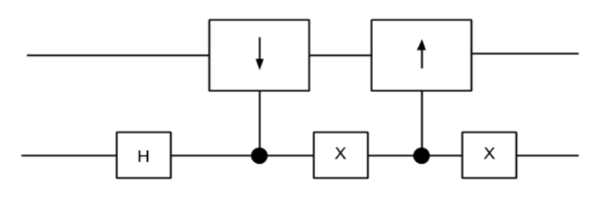


## Task B.1 - Quantum Walk Implementation

Implement a discrete quantum walk over 128 positions using seven position qubits and one coin qubit. Plot the circuit for ten iterations and compare it with Task 1.


### Our Solution


## Task B.2 - Measurement Distribution

Plot the simulated distributions after 10, 20, and 30 iterations. Compare them with a classical random walk and discuss symmetry, spreading speed, and interference.


### Our Solution


## Task B.3 - Initial Condition in Superposition

Initialize the walker in a superposition of two positions, plot the distribution after 30 iterations, and compare it with the earlier distributions.


### Our Solution


## Task B.4 - ROTY and Biased Quantum Walk

Replace the coin operator with ROTY. Discuss how it changes the probability distribution and how it can produce a biased quantum walk.


### Our Solution


# Bonus Exercise - Grover's Algorithm

Complete this bonus in the separate notebook supplied with the assignment.


## AI Assistance Disclosure

### Tools and models used

### Per-task usage

### Prompts or interaction summary

### Validation
